
# **Lab1.2 -- Background Mathematics**

- This Python notebook is designed to help you practice writing code and to introduce the mathematical ideas needed for understanding deep learning.
- The content is intended to be approachable, and some of the material may already be familiar.
- Mathematics is best learned through active engagement. Simply watching lectures or reading is not enough—working through examples and experimenting on your own is essential.
- Complete the notebook step by step by executing each cell. Sections marked **TODO** require you to implement the missing code. Conceptual questions are also included throughout the notebook.


In [1]:
# Imports math library
import numpy as np
# Imports plotting library
import matplotlib.pyplot as plt

**Linear functions**<br> We will be using the term *linear equation* to mean a weighted sum of inputs plus an offset. If there is just one input $x$, then this is a straight line:

\begin{equation}y=\beta+\omega x,\end{equation}

where $\beta$ is the y-intercept of the linear and $\omega$ is the slope of the line. When there are two inputs $x_{1}$ and $x_{2}$, then this becomes:

\begin{equation}y=\beta+\omega_1 x_1 + \omega_2 x_2.\end{equation}

Any other functions are by definition **non-linear**.




In [2]:
# Define a linear function with just one input, x
def linear_function_1D(x,beta,omega):
  # TODO -- replace the code line below with formula for 1D linear equation
  y = beta + omega * x
  return y

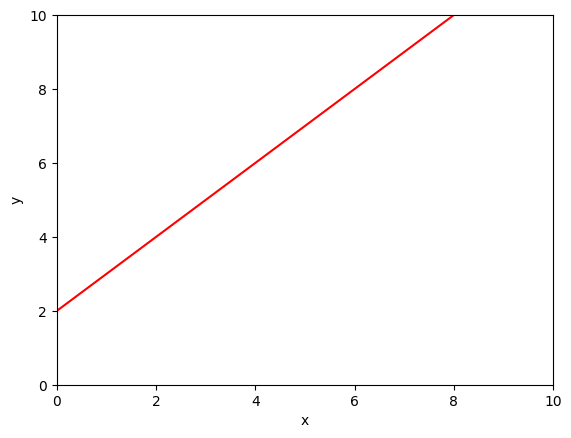

In [3]:
# Plot the 1D linear function

# Define an array of x values from 0 to 10 with increments of 0.01
# https://numpy.org/doc/stable/reference/generated/numpy.arange.html
x = np.arange(0.0,10.0, 0.01)
# Compute y using the function you filled in above
beta = 2.0; omega = 1.0

y = linear_function_1D(x,beta,omega)

# Plot this function
fig, ax = plt.subplots()
ax.plot(x,y,'r-')
ax.set_ylim([0,10]);ax.set_xlim([0,10])
ax.set_xlabel('x'); ax.set_ylabel('y')
plt.show()



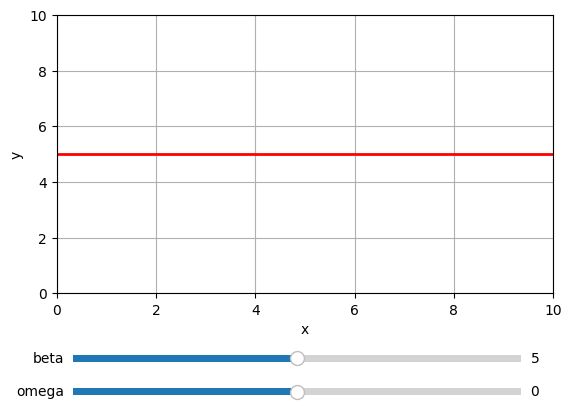

In [4]:
# TODO -- experiment with changing the values of beta and omega
# to understand what they do.  Try to make a line
import matplotlib.widgets
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

def linear_function_1D(x, beta, omega):
    return beta + omega * x

# Data
x = np.linspace(0, 10, 400)

# Initial parameters
beta = 5.0
omega = 0.0
y = linear_function_1D(x, beta, omega)

# Figure and plot
fig, ax = plt.subplots()
plt.subplots_adjust(bottom=0.3)

(line,) = ax.plot(x, y, 'r-', lw=2)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid(True)

# Slider axes
ax_beta = plt.axes([0.15, 0.15, 0.7, 0.03])
ax_omega = plt.axes([0.15, 0.08, 0.7, 0.03])

# Sliders
beta_slider = Slider(ax_beta, 'beta', -5.0, 15.0, valinit=beta)
omega_slider = Slider(ax_omega, 'omega', -5.0, 5.0, valinit=omega)

# Update function
def update(val):
    y_new = linear_function_1D(
        x,
        beta_slider.val,
        omega_slider.val
    )
    line.set_ydata(y_new)
    fig.canvas.draw_idle()

beta_slider.on_changed(update)
omega_slider.on_changed(update)

plt.show()



# that crosses the y-axis at y=10 and the x-axis at x=5

Now let's investigate a 2D linear function

In [5]:
# Code to draw 2D function -- read it so you know what is going on, but you don't have to change it
def draw_2D_function(x1_mesh, x2_mesh, y):
    fig, ax = plt.subplots()
    fig.set_size_inches(7,7)
    pos = ax.contourf(x1_mesh, x2_mesh, y, levels=256 ,cmap = 'hot', vmin=-10,vmax=10.0)
    fig.colorbar(pos, ax=ax)
    ax.set_xlabel('x1');ax.set_ylabel('x2')
    levels = np.arange(-10,10,1.0)
    ax.contour(x1_mesh, x2_mesh, y, levels, cmap='winter')
    plt.show()

In [6]:
# Define a linear function with two inputs, x1 and x2
def linear_function_2D(x1,x2,beta,omega1,omega2):
  # TODO -- replace the code line below with formula for 2D linear equation
  y = beta + omega1 * x1 + omega2 * x2
  return y

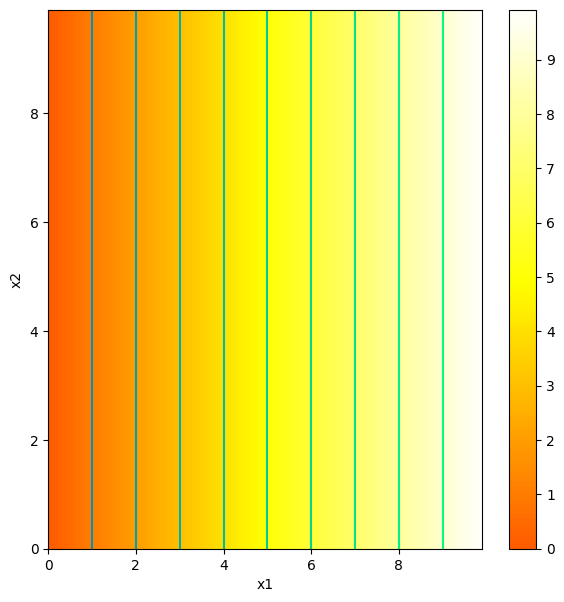

In [7]:
# Plot the 2D function

# Make 2D array of x and y points
x1 = np.arange(0.0, 10.0, 0.1)
x2 = np.arange(0.0, 10.0, 0.1)
x1,x2 = np.meshgrid(x1,x2)  # https://www.geeksforgeeks.org/numpy-meshgrid-function/

# Compute the 2D function for given values of omega1, omega2
beta = 0.0; omega1 = 1.0; omega2 = 0.0
y  = linear_function_2D(x1,x2,beta, omega1, omega2)

# Draw the function.
# Color represents y value (brighter = higher value)
# Black = -10 or less, White = +10 or more
# 0 = mid orange
# Lines are contours where value is equal
draw_2D_function(x1,x2,y)
# TODO
# Predict what this plot will look like if you set omega_1 to zero
# Change the code and see if you are right.

# TODO
# Predict what this plot will look like if you set omega_2 to zero
# Change the code and see if you are right.

# TODO
# Predict what this plot will look like if you set beta to -5
# Change the code and see if you are correct


Often we will want to compute many linear functions at the same time.  For example, we might have three inputs, $x_1$, $x_2$, and $x_3$ and want to compute two linear functions giving $y_1$ and $y_2$. Of course, we could do this by just running each equation separately,<br><br>

\begin{align}y_1 &=& \beta_1 + \omega_{11} x_1 + \omega_{12} x_2 + \omega_{13} x_3\\
y_2 &=& \beta_2 + \omega_{21} x_1 + \omega_{22} x_2 + \omega_{23} x_3.
\end{align}

However, we can write it more compactly with vectors and matrices:

\begin{equation}
\begin{bmatrix} y_1\\ y_2 \end{bmatrix} = \begin{bmatrix}\beta_{1}\\\beta_{2}\end{bmatrix}+ \begin{bmatrix}\omega_{11}&\omega_{12}&\omega_{13}\\\omega_{21}&\omega_{22}&\omega_{23}\end{bmatrix}\begin{bmatrix}x_{1}\\x_{2}\\x_{3}\end{bmatrix},
\end{equation}
or

\begin{equation}
\mathbf{y} = \boldsymbol\beta +\boldsymbol\Omega\mathbf{x}.
\end{equation}

for short.  Here, lowercase bold symbols are used for vectors.  Upper case bold symbols are used for matrices.



In [8]:
# Define a linear function with three inputs, x1, x2, and x_3
def linear_function_3D(x1,x2,x3,beta,omega1,omega2,omega3):
  # TODO -- replace the code below with formula for a single 3D linear equation
  y = beta + omega1 * x1 + omega2 * x2 + omega3 * x3
  return y

Let's compute two linear equations, using both the individual equations and the vector / matrix form and check they give the same result

In [9]:
# Define the parameters
beta1 = 0.5; beta2 = 0.2
omega11 =  -1.0 ; omega12 = 0.4; omega13 = -0.3
omega21 =  0.1  ; omega22 = 0.1; omega23 = 1.2

# Define the inputs
x1 = 4 ; x2 =-1; x3 = 2

# Compute using the individual equations
y1 = linear_function_3D(x1,x2,x3,beta1,omega11,omega12,omega13)
y2 = linear_function_3D(x1,x2,x3,beta2,omega21,omega22,omega23)
print("Individual equations")
print('y1 = %3.3f\ny2 = %3.3f'%((y1,y2)))

# Define vectors and matrices
beta_vec = np.array([[beta1],[beta2]])
omega_mat = np.array([[omega11,omega12,omega13],[omega21,omega22,omega23]])
x_vec = np.array([[x1], [x2], [x3]])

# Compute with vector/matrix form
y_vec = beta_vec+np.matmul(omega_mat, x_vec)
print("Matrix/vector form")
print('y1= %3.3f\ny2 = %3.3f'%((y_vec[0][0],y_vec[1][0])))


Individual equations
y1 = -4.500
y2 = 2.900
Matrix/vector form
y1= -4.500
y2 = 2.900


# Questions

1.  A single linear equation with three inputs (i.e. **linear_function_3D()**) associates a value y with each point in a 3D space ($x_1$,$x_2$,$x_3$).  Is it possible to visualize this?   What value is at position (0,0,0)?

2.  Write code to compute three linear equations with two inputs ($x_1$, $x_2$) using both the individual equations and the matrix form (you can make up any values for the inputs $\beta_{i}$ and the slopes $\omega_{ij}$.

# Answer
1. **Answer to Question 1:**

A single linear equation with three inputs has the form  

\begin{align}y &=&\beta + \omega_1 x_1 + \omega_2 x_2 + \omega_3 x_3\\
\end{align}

This equation maps every point \((x1, x2, x3)\) in 3D space to a single scalar output \(y\).

At the position (0,0,0), the value is simply the intercept term:  




\begin{align}
y &= \beta
\end{align}










In [11]:
### Answer 2
# Define three linear equations with two inputs
beta_3eq = np.array([[1.0], [0.5], [-2.0]])
omega_3eq = np.array([
    [2.0, -1.0],
    [0.5,  3.0],
    [-1.0, 2.0]
])

# Define the inputs as a column vector
x_2input = np.array([[4.0], [-1.0]])

# Compute using the individual equations
x1_2input = x_2input[0, 0]
x2_2input = x_2input[1, 0]

y1_3eq = beta_3eq[0, 0] + omega_3eq[0, 0] * x1_2input + omega_3eq[0, 1] * x2_2input
y2_3eq = beta_3eq[1, 0] + omega_3eq[1, 0] * x1_2input + omega_3eq[1, 1] * x2_2input
y3_3eq = beta_3eq[2, 0] + omega_3eq[2, 0] * x1_2input + omega_3eq[2, 1] * x2_2input

print(y1_3eq, y2_3eq, y3_3eq)

y_individual = np.array([[y1_3eq], [y2_3eq], [y3_3eq]])

# Compute using matrix form: y = beta + Omega @ x
y_matrix = beta_3eq + np.matmul(omega_3eq, x_2input)

print("Individual equations:")
print(y_individual)

print("\nMatrix form:")
print(y_matrix)

print("\nResults match:", np.allclose(y_individual, y_matrix))

10.0 -0.5 -8.0
Individual equations:
[[10. ]
 [-0.5]
 [-8. ]]

Matrix form:
[[10. ]
 [-0.5]
 [-8. ]]

Results match: True
